# 3. Puzzle generation (Objective O2)

The miner turns a player's mistakes into puzzles with exactly one good move at every turn of the solver, verified with Stockfish.

**Sources:** `eval/research/mined_uniqueness.json` (`scripts/revalidate_mined_puzzles.py`) and
`eval/research/mined_puzzles_summary.json` (`scripts/research/summarise_mined_puzzles.py`). The stored puzzles belong to
users, so only totals are published.

In [1]:
import pandas as pd
from nb_utils import ROOT, figures, load

pd.set_option('display.max_columns', None, 'display.width', 120)

## Re-checking the single-solution rule

Earlier puzzles were only checked on the first move. When the check was extended to every move of the solver, all stored puzzles were checked again.

In [2]:
check = load('eval/research/mined_uniqueness.json')
totals = check['totals']
print(check['rule'])
pd.Series(totals, name='puzzles').to_frame().T

every player move beats the second choice by 100 cp (first move at depth 18, later moves at depth 16)


,puzzles,multi_move,unchanged,cut,first_move_fails
puzzles,151,48,112,24,15


In [3]:
broke = totals['cut'] + totals['first_move_fails']
print(f"broke the rule: {broke} of {totals['puzzles']} ({broke / totals['puzzles']:.0%})")
print(f"retired: {totals['first_move_fails']}, shortened: {totals['cut']}")

broke the rule: 39 of 151 (26%)
retired: 15, shortened: 24


## The puzzles that remain

In [4]:
summary = load('eval/research/mined_puzzles_summary.json')
attempts = summary['attempts']
moves = pd.Series(summary['solver_moves']).rename(int)
maia = pd.Series(summary['maia_probabilities'])
pd.Series({
    'puzzles kept': summary['puzzles_kept'],
    'users': summary['users_with_puzzles'],
    'median mistake (cp)': summary['median_mistake_cp'],
    'median margin over the second best (cp)': summary['median_margin_cp'],
    'one solver move': f'{moves[1] / moves.sum():.0%}',
    'Maia median': f'{maia.median():.0%}',
    'Maia below 10%': f'{(maia < .10).mean():.0%}',
    'Maia above 50%': f'{(maia > .50).mean():.0%}',
    'solved by owners': f"{attempts['mined_solved'] / attempts['mined_total']:.1%} of {attempts['mined_total']} attempts",
}, name='value').to_frame()

,value
puzzles kept,136
users,6
median mistake (cp),324.0
median margin over the second best (cp),204.5
one solver move,82%
Maia median,27%
Maia below 10%,19%
Maia above 50%,24%
solved by owners,87.9% of 91 attempts


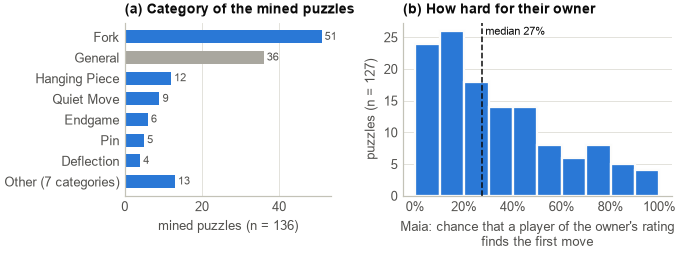

In [5]:
figures.mined()

## Observations

- The re-check mattered: 39 of 151 stored puzzles (26%) broke the rule. 15 were retired and 24 shortened, leaving 136.
- The best move beats the second best by a median of 205 centipawns, twice the required margin.
- Most puzzles need one solver move, because a line stops as soon as either side has more than one good option.
- Forks dominate, and a quarter of the puzzles have no specific motif (General), so the selector cannot target those directly.
- Maia suggests that about one puzzle in five would be found by fewer than 10% of players at the owner's rating.
- Owners still solved 87.9% of their mined puzzles, so a position from one's own game is easier than its content suggests.